### Decision Tree Regressor

In [1]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

In [8]:
df = load_diabetes(as_frame=True).frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [10]:
X = df.drop("target",axis=1)
y = df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [11]:
X_train.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
17,0.070769,0.050680,0.012117,0.056301,0.034206,0.049416,-0.039719,0.034309,0.027364,-0.001078
66,-0.009147,0.050680,-0.018062,-0.033213,-0.020832,0.012152,-0.072854,0.071210,0.000272,0.019633
137,0.005383,-0.044642,0.049840,0.097615,-0.015328,-0.016345,-0.006584,-0.002592,0.017036,-0.013504
245,-0.027310,-0.044642,-0.035307,-0.029770,-0.056607,-0.058620,0.030232,-0.039493,-0.049872,-0.129483
31,-0.023677,-0.044642,-0.065486,-0.081413,-0.038720,-0.053610,0.059685,-0.076395,-0.037129,-0.042499


In [12]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor()

model.fit(X_train , y_train)

DecisionTreeRegressor()

In [18]:
from sklearn.metrics import r2_score, mean_squared_error,accuracy_score

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training MSE: ", mean_squared_error(y_train , y_pred_train))
print("Testing MSE: ", mean_squared_error(y_test , y_pred_test))
print("Training R2 Score: ", r2_score(y_train , y_pred_train))
print("Testing R2 Score: ", r2_score(y_test , y_pred_test))

Training MSE:  0.0
Testing MSE:  5220.606741573034
Training R2 Score:  1.0
Testing R2 Score:  0.014636237432285482


training MSE is 0 and r2 score also 1 so model is overfitting(definitely)

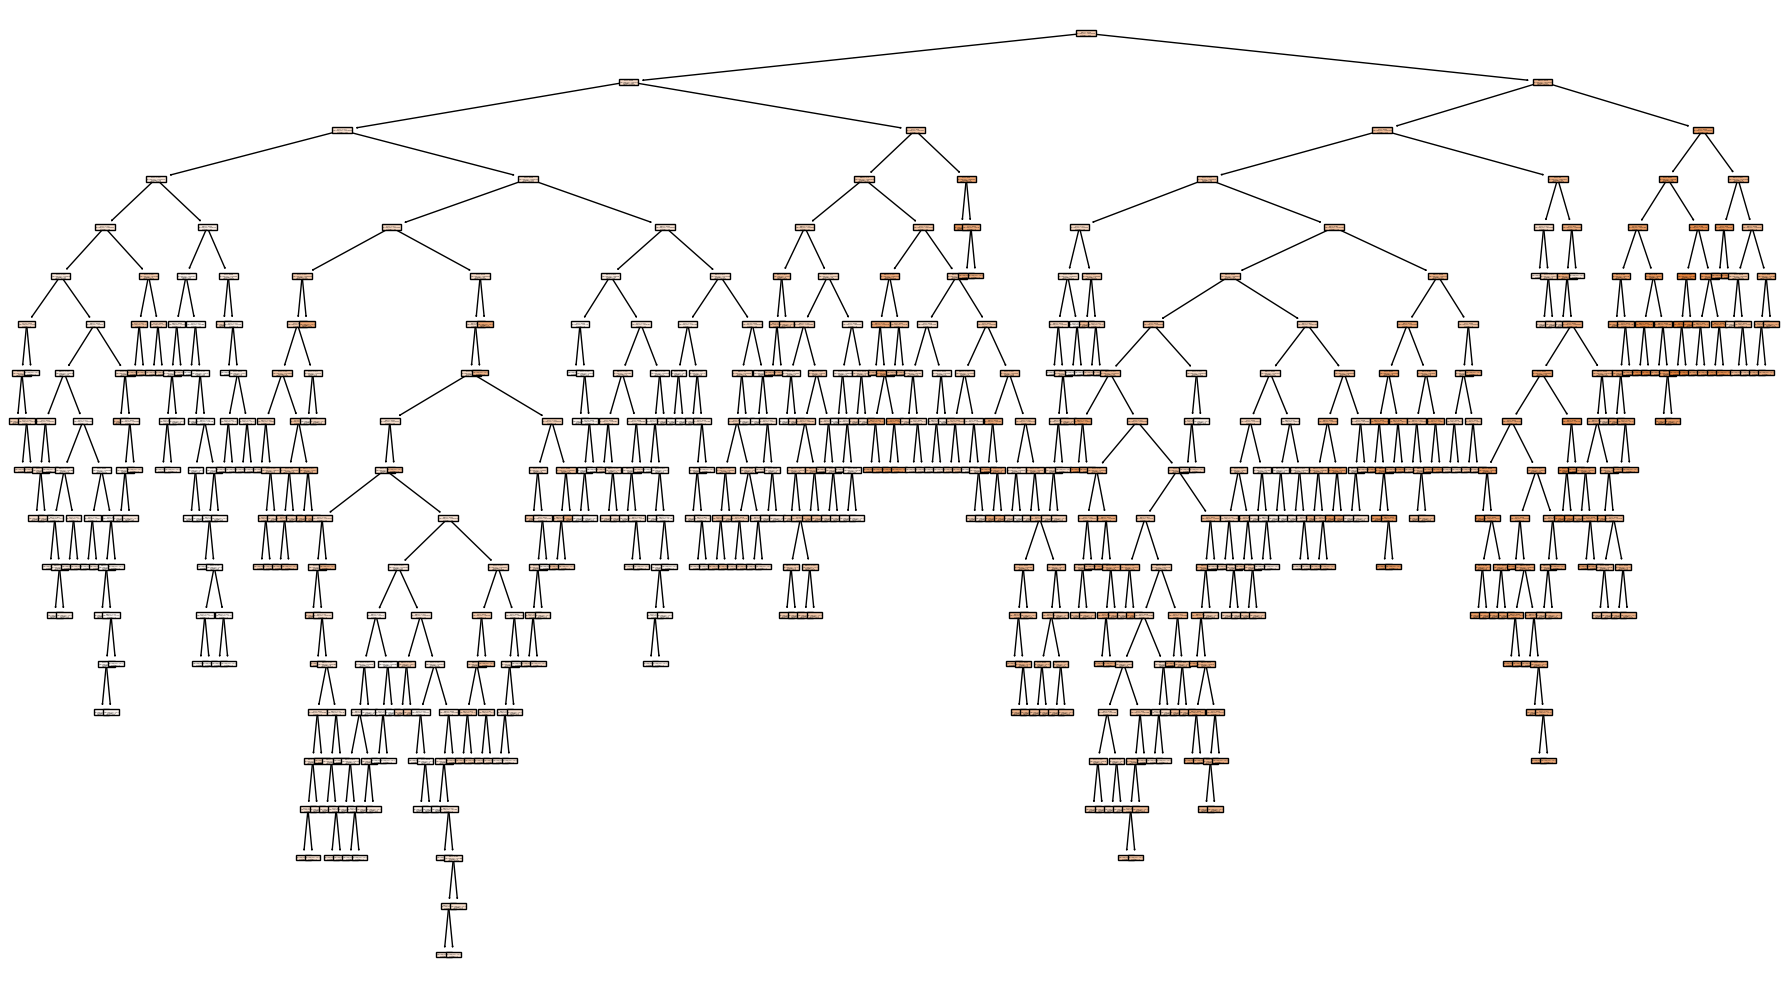

In [19]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18,10))
plot_tree(
    model,
    feature_names=X.columns,
    filled=True
)

plt.tight_layout()
plt.show()

- Very big nd complex tree so so thereis overfitting as well 

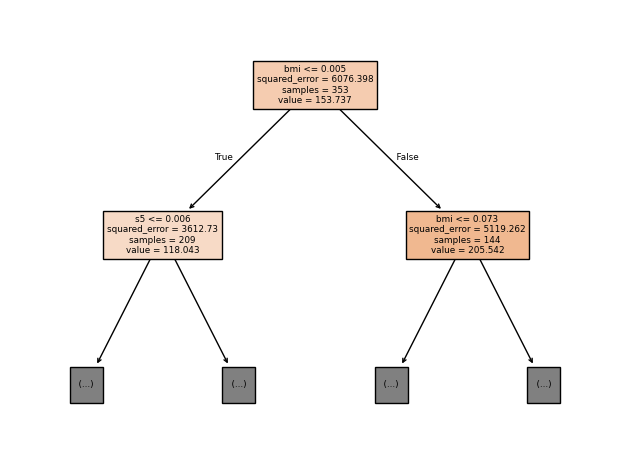

In [22]:
plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    max_depth=1
)

plt.tight_layout()
plt.show()

pre-pruning

Training MSE:  2712.48075111857
Testing MSE:  3258.996155814711
Training R2 Score:  0.5536038381089772
Testing R2 Score:  0.38488055637002505


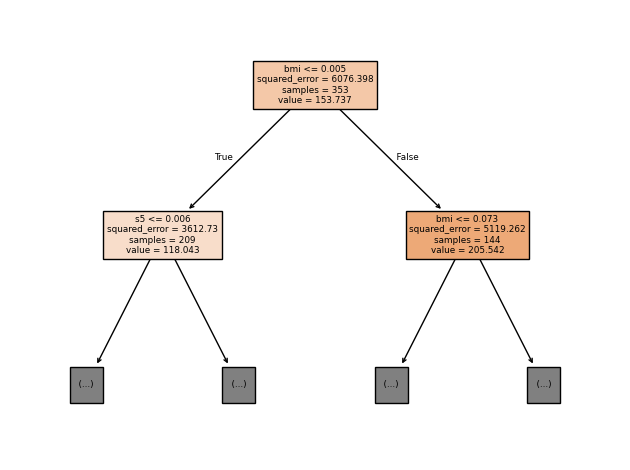

In [24]:
model = DecisionTreeRegressor(max_depth=7,min_samples_leaf=20)

model.fit(X_train , y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training MSE: ", mean_squared_error(y_train , y_pred_train))
print("Testing MSE: ", mean_squared_error(y_test , y_pred_test))
print("Training R2 Score: ", r2_score(y_train , y_pred_train))
print("Testing R2 Score: ", r2_score(y_test , y_pred_test))
# both r2 score must be close 

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    max_depth=1
)

plt.tight_layout()
plt.show()